# TryOn with Scraped Images Evaluation

Goal: Determine whether Gemini VTO survives scraped product images, and identify failure modes by image type (model-wearing vs. flat-lay vs. lifestyle).

**Note**: This notebook uses mock data from `rd-16-coverage.json`. The image URLs are synthetic and should not be fetched. Real VTO calls will wire to `src/ai/tryon.ts` once live scraping is implemented.

In [2]:
import json
import pandas as pd
import numpy as np
from pathlib import Path

# Load coverage JSON
with open('../outputs/rd-16-coverage.json', 'r') as f:
    coverage_data = json.load(f)

df = pd.DataFrame(coverage_data)
print(f"Loaded {len(df)} products")

Loaded 33 products


In [3]:
# Select 10 distinct products (one per host where possible)
unique_hosts = df['host'].unique()
selected_products = []

for host in unique_hosts[:10]:  # Take first 10 unique hosts
    host_products = df[df['host'] == host]
    selected_product = host_products.iloc[0]  # Take first product from each host
    selected_products.append(selected_product)

selected_df = pd.DataFrame(selected_products)
print(f"Selected {len(selected_df)} products from {len(selected_df['host'].unique())} hosts")
print(selected_df['host'].value_counts())

Selected 10 products from 10 hosts
host
www2.hm.com                 1
www.gapcanada.ca            1
oldnavy.gapcanada.ca        1
rothys.com                  1
kirrinfinch.com             1
www.beefcakeswimwear.com    1
www.zara.com                1
www.asos.com                1
www.etsy.com                1
www.depop.com               1
Name: count, dtype: int64


In [6]:
# Create 30-row eval grid (3 image types per product)
image_types = ['model_wearing', 'flat_lay', 'lifestyle']
eval_rows = []

# Person reference image
person_image_path = '../inputs/20260524_174630.jpg'

for _, product_row in selected_df.iterrows():
    for img_type in image_types:
        # Simulate image type by appending query parameter
        garment_image_url = f"{product_row['fields']['image']}?type={img_type}"
        
        eval_rows.append({
            'product_url': product_row['url'],
            'image_type': img_type,
            'garment_image_url': garment_image_url,
            'person_image_path': person_image_path,
            'vto_output_path': None,  # To be filled after VTO runs
            'realism_rating': None,   # To be filled by Aryan
            'failure_mode': None      # To be filled after analysis
        })

eval_df = pd.DataFrame(eval_rows)
print(f"Created {len(eval_df)} evaluation rows (3 per product)")

Created 30 evaluation rows (3 per product)


In [8]:
# VTO stub function
def run_vto(person_img, garment_img, prompt):
    """
    Stub function for VTO calls.
    
    TODO: Wire to src/ai/tryon.ts via subprocess or port the logic here.
    Real implementation should call Gemini VTO with the person and garment images.
    """
    raise NotImplementedError("Wire to src/ai/tryon.ts via subprocess or port")

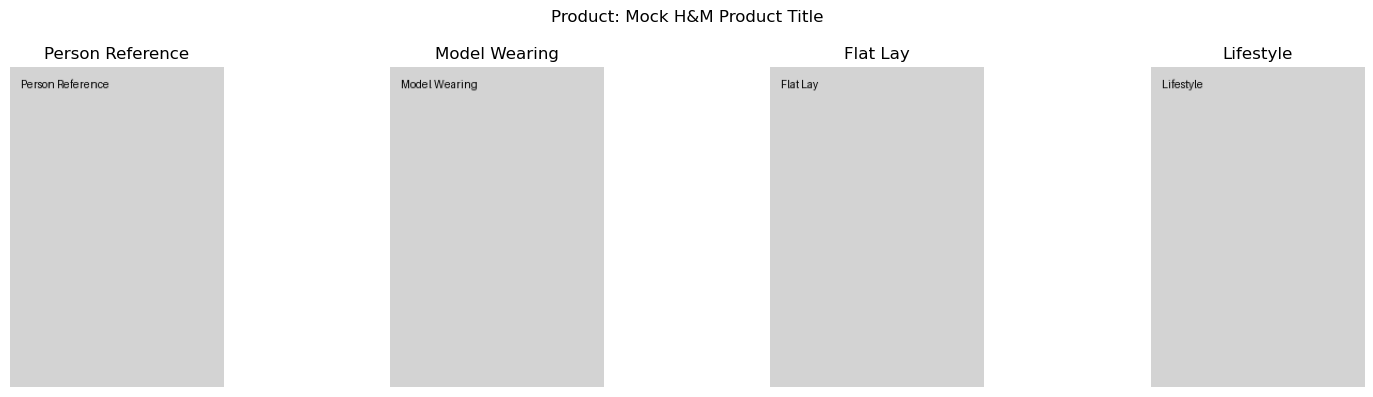

In [10]:
# Demo block: render placeholder grids
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import io

# Create placeholder person image (since we don't have the real one)
def create_placeholder_image(text, size=(200, 300)):
    img = Image.new('RGB', size, color='lightgray')
    draw = ImageDraw.Draw(img)
    # Try to add text
    try:
        draw.text((10, 10), text, fill='black')
    except:
        # If font issues, just return gray image
        pass
    return img

# Display one product example
sample_product = selected_df.iloc[0]
person_placeholder = create_placeholder_image("Person Reference")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Person reference
axes[0].imshow(person_placeholder)
axes[0].set_title("Person Reference")
axes[0].axis('off')

# Three image types
for i, img_type in enumerate(image_types):
    garment_placeholder = create_placeholder_image(f"{img_type.replace('_', ' ').title()}")
    axes[i+1].imshow(garment_placeholder)
    axes[i+1].set_title(img_type.replace('_', ' ').title())
    axes[i+1].axis('off')

plt.suptitle(f"Product: {sample_product['fields']['title']}")
plt.tight_layout()
plt.show()

In [12]:
# Save evaluation grid
eval_df.to_csv('../outputs/18-tryon-eval.csv', index=False)

# Also save as JSON
eval_json = eval_df.to_dict('records')
with open('../outputs/18-tryon-eval.json', 'w') as f:
    json.dump(eval_json, f, indent=2)

print("Evaluation grid saved to:")
print("- ../outputs/18-tryon-eval.csv")
print("- ../outputs/18-tryon-eval.json")

print("\nFirst few rows of evaluation grid:")
print(eval_df.head())

Evaluation grid saved to:
- ../outputs/18-tryon-eval.csv
- ../outputs/18-tryon-eval.json

First few rows of evaluation grid:
                                         product_url     image_type  \
0  https://www2.hm.com/en_ca/productpage.13254940...  model_wearing   
1  https://www2.hm.com/en_ca/productpage.13254940...       flat_lay   
2  https://www2.hm.com/en_ca/productpage.13254940...      lifestyle   
3  https://www.gapcanada.ca/browse/product.do?pid...  model_wearing   
4  https://www.gapcanada.ca/browse/product.do?pid...       flat_lay   

                                   garment_image_url  \
0  https://mock.example.com/image.jpg?type=model_...   
1   https://mock.example.com/image.jpg?type=flat_lay   
2  https://mock.example.com/image.jpg?type=lifestyle   
3  https://mock.example.com/image.jpg?type=model_...   
4   https://mock.example.com/image.jpg?type=flat_lay   

               person_image_path vto_output_path realism_rating failure_mode  
0  ../inputs/20260524_174630.jpg

In [14]:
# Rating aggregation scaffolding (ready to run once ratings are filled)
def analyze_ratings(eval_df_with_ratings):
    """Analyze ratings once they are filled in"""
    # Filter out rows without ratings
    rated_df = eval_df_with_ratings.dropna(subset=['realism_rating'])
    
    if len(rated_df) == 0:
        print("No ratings filled yet")
        return
    
    # Mean realism by image type
    mean_by_type = rated_df.groupby('image_type')['realism_rating'].mean()
    print("Mean realism by image type:")
    print(mean_by_type)
    
    # Failure mode tally
    failure_modes = rated_df['failure_mode'].value_counts()
    print("\nFailure modes:")
    print(failure_modes)
    
    # Pass/fail decision
    overall_mean = rated_df['realism_rating'].mean()
    print(f"\nOverall mean realism: {overall_mean:.2f}")
    print(f"Pass bar (≥3.5): {'PASS' if overall_mean >= 3.5 else 'FAIL'}")
    
    # Per-type comparison
    if 'flat_lay' in mean_by_type and 'model_wearing' in mean_by_type:
        flat_lay_mean = mean_by_type['flat_lay']
        model_wearing_mean = mean_by_type['model_wearing']
        if flat_lay_mean - model_wearing_mean > 0.8:
            print("\nWarning: model_wearing lags flat_lay by >0.8 - consider dropping model_wearing")

# Call with current (empty) data to show structure
analyze_ratings(eval_df)

No ratings filled yet
